<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula25b%20-%20perceptron%20vectorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [120]:
import numpy as np

def create_dataset(n=20, coefs=[1, 1], intercept=-1):
  X = np.random.rand(n, 2)
  y = X @ coefs + intercept
  y = np.sign(y)
  return X, y

X, y = create_dataset()
print(X)
print(y)

[[0.87312696 0.20960052]
 [0.0591013  0.22998212]
 [0.74968434 0.74879604]
 [0.14369861 0.41678765]
 [0.98102382 0.53678566]
 [0.70627621 0.24762053]
 [0.90106132 0.73247989]
 [0.62598334 0.70108875]
 [0.02744383 0.75918196]
 [0.62318059 0.29014305]
 [0.5438979  0.43178686]
 [0.86544867 0.59056348]
 [0.15738301 0.10152972]
 [0.41174362 0.70349083]
 [0.22253156 0.64466544]
 [0.09372275 0.63706625]
 [0.32674183 0.42499059]
 [0.65648278 0.25867742]
 [0.34248124 0.33146954]
 [0.09938596 0.63024093]]
[ 1. -1.  1. -1.  1. -1.  1.  1. -1. -1. -1.  1. -1.  1. -1. -1. -1. -1.
 -1. -1.]


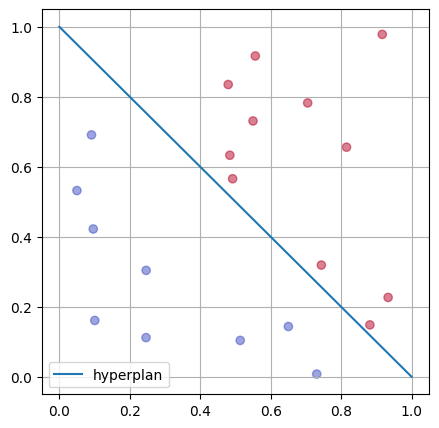

In [121]:
from matplotlib import pyplot as plt

def plot_dataset(X, y):
  plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", alpha=0.5)
  plt.grid(True)

def plot_hyperplan(coefs, intercept, legend="hyperplan"):
  xs = np.array([0,1])
  ys = -(coefs[0] * xs + intercept) / coefs[1]
  plt.plot(xs, ys, label=legend)
  plt.legend()

coefs = [1, 1]
intercept = -1
X, y = create_dataset(20, coefs, intercept)

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept)
plt.show()

accuracy: 1.0
coefs: [32.67097456 38.7190946 ]


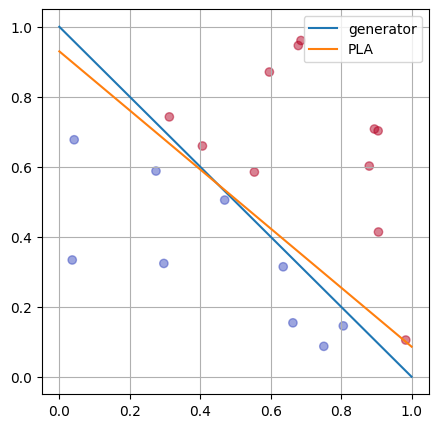

In [124]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

class Perceptron(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=100):
    self.max_iter = max_iter

  def fit(self, X, y):
    self.coefs = np.zeros(X.shape[1])
    self.intercept = 0
    for _ in range(self.max_iter):
      cost = 0
      logits = X @ self.coefs + self.intercept
      y_pred = np.sign(logits)
      error = y - y_pred
      self.coefs += X.T @ error
      self.intercept += error.sum()
      cost = np.sum(error**2)
      if cost == 0:
        break
    return self

  def predict(self, X):
    logits = X @ self.coefs + self.intercept
    y_pred = np.sign(logits)
    return y_pred

coefs = [1, 1]
intercept = -1
X, y = create_dataset(20, coefs, intercept)

clf = Perceptron()
clf.fit(X, y)
y_pred = clf.predict(X)
print(f"accuracy: {accuracy_score(y, y_pred)}")
print(f"coefs: {clf.coefs}")

plt.figure(figsize=(5, 5))
plot_dataset(X, y)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "PLA")
plt.show()

accuracy: 0.955


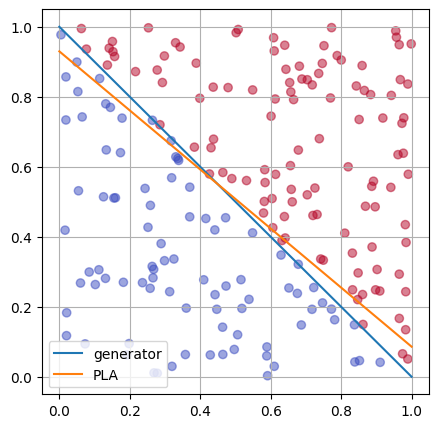

In [129]:
X_test, y_test = create_dataset(200, coefs, intercept)
y_pred = clf.predict(X_test)
print(f"accuracy: {accuracy_score(y_test, y_pred)}")

plt.figure(figsize=(5, 5))
plot_dataset(X_test, y_test)
plot_hyperplan(coefs, intercept, "generator")
plot_hyperplan(clf.coefs, clf.intercept, "PLA")
plt.show()